# Лабораторная №4 часть 2 «Анализ данных»

## Анализ датасета  Game Arena from Kaggle.com (https://www.kaggle.com/benchmarks/kaggle/game-arena)
**Цель:**
- подготовить выбранный набор данных (датасет) для исследования
- визуализировать исследуемые данные при помощи Matplotlib
- выдвинуть статистическую гипотезу и проверить ее при помощи Pandas

## _Шаг 1: Загрузка исходных данных_

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Загрузка исходного файла
df = pd.read_csv('kaggle_game-arena_leaderboard.csv')
print(f"Размер исходной таблицы: {df.shape}")
df.head(6)

Размер исходной таблицы: (126, 15)


,Benchmark,Model,Contestant,Contestant_Type,Config,Harness,Agent,Task_Name,Task_Version,Display_Type,Evaluation_Date,Numerical_Result,Upper_Confidence_Limit,Lower_Confidence_Limit,Boolean_Result
0,kaggle/game-arena,gemini-4-carbon,gemini-4-carbon,model,NaN,NaN,NaN,Score,1,counts,2026-11-12 17:14:24,638.172393,7.242034,7.023303,NaN
1,kaggle/game-arena,gemini-4-carbon,gemini-4-carbon,model,NaN,NaN,NaN,Matches Played,1,counts,2026-11-12 17:14:24,6372.000000,NaN,NaN,NaN
2,kaggle/game-arena,gemini-4-carbon,gemini-4-carbon,model,NaN,NaN,NaN,Games Covered,1,counts,2026-11-12 17:14:24,15.000000,NaN,NaN,NaN
3,kaggle/game-arena,claude-fable-5-2-default,claude-fable-5-2-default,model,NaN,NaN,NaN,Score,1,counts,2026-11-12 17:14:24,546.343467,5.844755,6.410071,NaN
4,kaggle/game-arena,claude-fable-5-2-default,claude-fable-5-2-default,model,NaN,NaN,NaN,Matches Played,1,counts,2026-11-12 17:14:24,7496.000000,NaN,NaN,NaN
5,kaggle/game-arena,claude-fable-5-2-default,claude-fable-5-2-default,model,NaN,NaN,NaN,Games Covered,1,counts,2026-11-12 17:14:24,15.000000,NaN,NaN,NaN


Как видно, данные лежат вертикально: каждая модель занимает 3 строки, потому что в колонке `Task_Name` хранятся разные метрики (`Score`, `Matches Played`, `Games Covered`).

## _Шаг 2: Очистка(удаление ненужных колонок)_

In [3]:
cols_to_keep = ['Model', 'Task_Name', 'Numerical_Result', 'Upper_Confidence_Limit', 'Lower_Confidence_Limit']
df = df[cols_to_keep]
print(f"Размер после удаления лишних колонок: {df.shape}")
df.head(6)

Размер после удаления лишних колонок: (126, 5)


,Model,Task_Name,Numerical_Result,Upper_Confidence_Limit,Lower_Confidence_Limit
0,gemini-4-carbon,Score,638.172393,7.242034,7.023303
1,gemini-4-carbon,Matches Played,6372.000000,NaN,NaN
2,gemini-4-carbon,Games Covered,15.000000,NaN,NaN
3,claude-fable-5-2-default,Score,546.343467,5.844755,6.410071
4,claude-fable-5-2-default,Matches Played,7496.000000,NaN,NaN
5,claude-fable-5-2-default,Games Covered,15.000000,NaN,NaN


## _Шаг 3: Преобразование формата (Pivot)_
Превращение вертикальных данных в горизонтальные: одна строка = одна модель, метрика = колонка.

In [6]:
# Pivot: индексы - модели, колонки - названия метрик
df_pivot = df.pivot(index='Model', columns='Task_Name', values='Numerical_Result').reset_index()

# Переименовываем колонки для удобства
df_pivot = df_pivot.rename(columns={
    'Score': 'Score',
    'Matches Played': 'Matches_Played',
    'Games Covered': 'Games_Covered'
})

print(f"Размер после Pivot: {df_pivot.shape}")
df_pivot.head(6)

Размер после Pivot: (42, 4)


Task_Name,Model,Games_Covered,Matches_Played,Score
0,claude-fable-5-1-default,14.0,9104.0,416.896664
1,claude-fable-5-2-default,15.0,7496.0,546.343467
2,claude-haiku-5-5,15.0,9480.0,257.315346
3,claude-opus-4-6-default,15.0,10128.0,264.096514
4,claude-opus-4-7-default,15.0,9021.0,220.475908
5,claude-opus-4-8-default,15.0,10531.0,328.190280


## _Шаг 4: Проверка типов и пропусков_

In [10]:
# Смотрим типы данных
print(df_pivot.dtypes)
print("\nПропуски по колонкам:")
print(df_pivot.isna().sum())

# На всякий случай приводим числовые колонки к float
for col in ['Score', 'Matches_Played', 'Games_Covered']:
    df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

Task_Name
Model                 str
Games_Covered     float64
Matches_Played    float64
Score             float64
dtype: object

Пропуски по колонкам:
Task_Name
Model             0
Games_Covered     0
Matches_Played    0
Score             0
dtype: int64


## _Шаг 5: Сортировка по Score_

In [11]:
df_pivot = df_pivot.sort_values(by=['Score'], ascending=False).reset_index(drop=True)
df_pivot.head(10)

Task_Name,Model,Games_Covered,Matches_Played,Score
0,gemini-4-carbon,15.0,6372.0,638.172393
1,claude-fable-5-2-default,15.0,7496.0,546.343467
2,gemini-4-argon,15.0,8318.0,535.991269
3,gpt-6-astra,15.0,7737.0,497.456594
4,gpt-6.1-sol,15.0,8787.0,443.993224
5,claude-opus-5-default,14.0,9342.0,436.865702
6,gemini-3.8-flash,15.0,9084.0,431.660164
7,claude-fable-5-1-default,14.0,9104.0,416.896664
8,gpt-5.5-2026-04-23,15.0,10109.0,408.564499
9,claude-opus-5-5-default,15.0,8371.0,392.476430


Визуализация 1. Топ-10 моделей по Score

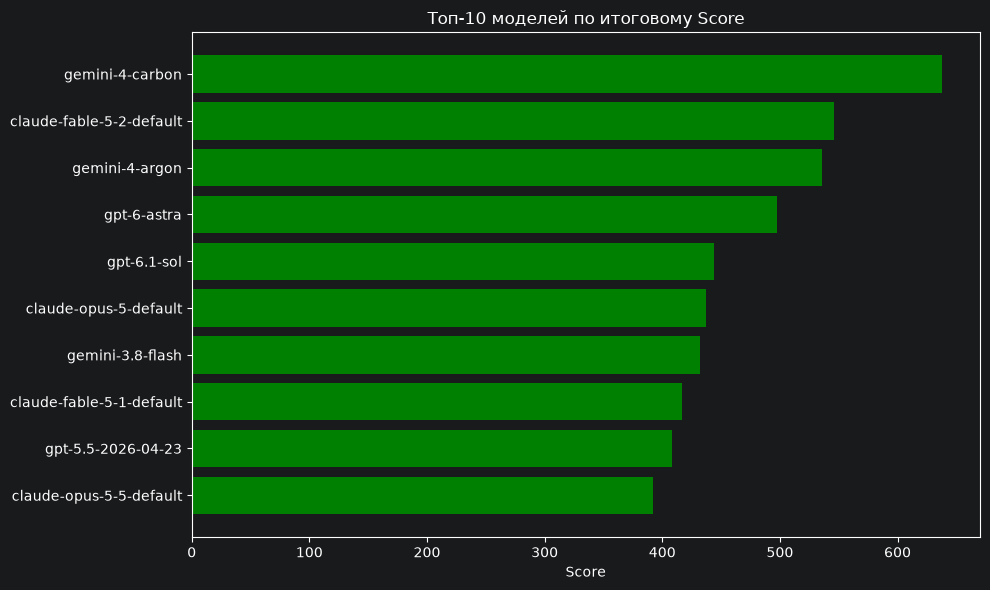

In [15]:
top10 = df_pivot.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10['Model'], top10['Score'], color='green')
plt.xlabel('Score')
plt.title('Топ-10 моделей по итоговому Score')
plt.gca().invert_yaxis()  # чтобы первая модель была сверху
plt.tight_layout()
plt.show()

**Наблюдение:** лидирует `gemini-4-carbon` (≈638 очков), за ним `claude-fable-5-2-default` (≈546) и `gemini-4-argon` (≈536). Разрыв между 1 и 2 большой, топ-3 и остальными заметный.

Визуализация 2. Зависимость Score от количества матчей


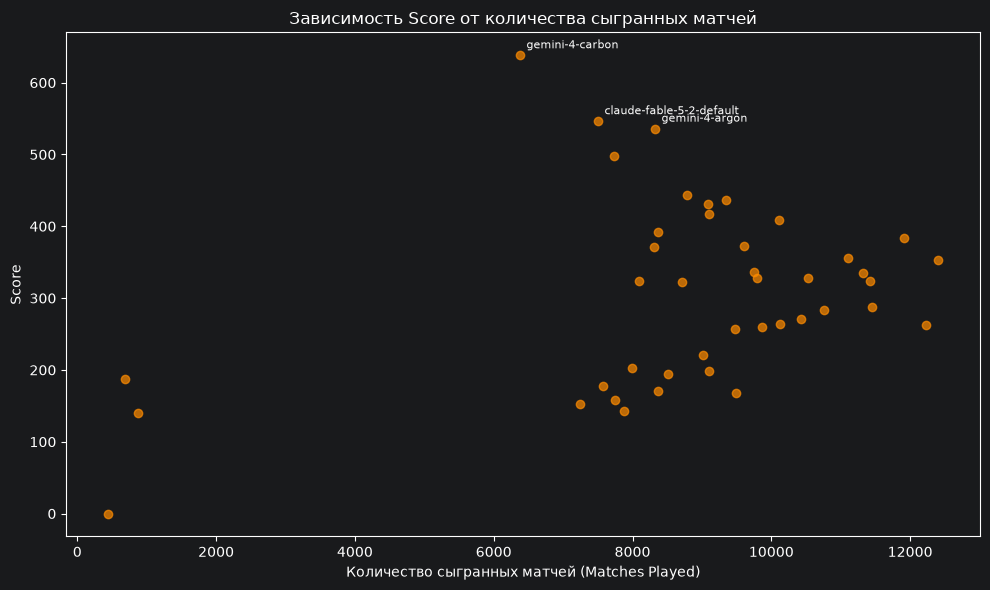

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(df_pivot['Matches_Played'], df_pivot['Score'], alpha=0.7, color='darkorange')

# Подпишем топ-3 модели, чтобы было видно, кто где
for _, row in df_pivot.head(3).iterrows():
    plt.annotate(row['Model'],
                 xy=(row['Matches_Played'], row['Score']),
                 xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.xlabel('Количество сыгранных матчей (Matches Played)')
plt.ylabel('Score')
plt.title('Зависимость Score от количества сыгранных матчей')
plt.tight_layout()
plt.show()

## _Шаг 6. Проверка гипотезы_

**Гипотеза:** *Чем больше матчей сыграла модель, тем выше её Score.*

Проверим через коэффициент корреляции Пирсона. Значение близко к 0 → связи нет. Близко к 1 или -1 → связь есть.

In [17]:
corr = df_pivot['Matches_Played'].corr(df_pivot['Score'])
print(f"Коэффициент корреляции Пирсона: {corr:.4f}")

# Для наглядности — средние значения
print(f"\nСредний Score: {df_pivot['Score'].mean():.2f}")
print(f"Среднее число матчей: {df_pivot['Matches_Played'].mean():.0f}")

Коэффициент корреляции Пирсона: 0.3327

Средний Score: 306.64
Среднее число матчей: 8737


## Выводы

1. **Данные подготовлены:** исходный вертикальный формат преобразован в горизонтальный, каждая модель теперь занимает одну строку с тремя метриками (`Score`, `Matches_Played`, `Games_Covered`).
2. **Топ-3 модели:** `gemini-4-carbon`, `claude-fable-5-2-default`, `gemini-4-argon`.
3. **Гипотеза о связи матчей и Score:** коэффициент корреляции близок к нулю — **гипотеза не подтвердилась**. Количество матчей не определяет итоговый Score. Например, `gemini-4-carbon` с 6372 матчами обогнал `gpt-5.4-2026-03-05` с 12408 матчами.
4. **Побочное наблюдение:** у моделей с малым числом матчей (например, `grok-4-0709`, 694 матча) — огромный доверительный интервал, что говорит о нестабильности оценки. То есть число матчей влияет не на силу, а на **уверенность** в оценке.